# 01 · Heart Disease — Exploratory Data Analysis

**Dataset:** UCI Heart Disease (Kaggle redo, `redwankarimsony/heart-disease-data`) — 920 patients across 4 hospitals.

**Goal (Phase 2):** understand the raw data, apply and document the cleaning
rules, explore every feature, and record the decisions (dropping `dataset`, the
`chol`/`trestbps` zero handling, whether `ca` stays numeric) that the downstream
preprocessing pipeline relies on.

Cleaning logic lives in `src/data_loader.py` so the notebook and the production
pipeline share one definition.

## 0 · Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import RANDOM_STATE, clean_heart_data, load_raw

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
pd.set_option("display.max_columns", 100)

RAW_CSV = PROJECT_ROOT / "data" / "raw" / "heart_disease_uci.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROCESSED_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name, fig=None):
    fig = fig or plt.gcf()
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


print("random_state:", RANDOM_STATE)
print("figures ->", FIG_DIR.relative_to(PROJECT_ROOT))

random_state: 42
figures -> data\processed\figures


## 1 · Data Understanding

In [2]:
raw = load_raw(RAW_CSV)
print("shape:", raw.shape)
raw.head()

shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [4]:
raw.dtypes.to_frame("dtype")

,dtype
id,int64
age,int64
sex,str
dataset,str
cp,str
trestbps,float64
chol,float64
fbs,object
restecg,str
thalch,float64


In [5]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


In [6]:
missing = pd.DataFrame({
    "missing": raw.isna().sum(),
    "pct": (raw.isna().mean() * 100).round(1),
}).sort_values("missing", ascending=False)
missing

,missing,pct
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


In [7]:
# Duplicates only surface once the row id (and hospital source) is removed.
print("exact duplicate rows (raw)                 :", raw.duplicated().sum())
print("exact duplicates after dropping id/dataset :",
      raw.drop(columns=["id", "dataset"]).duplicated().sum())

print("\nclinically implausible zeros (to become NaN):")
print("  chol == 0     :", int((raw["chol"] == 0).sum()))
print("  trestbps == 0 :", int((raw["trestbps"] == 0).sum()))

exact duplicate rows (raw)                 : 0
exact duplicates after dropping id/dataset : 2

clinically implausible zeros (to become NaN):
  chol == 0     : 172
  trestbps == 0 : 1


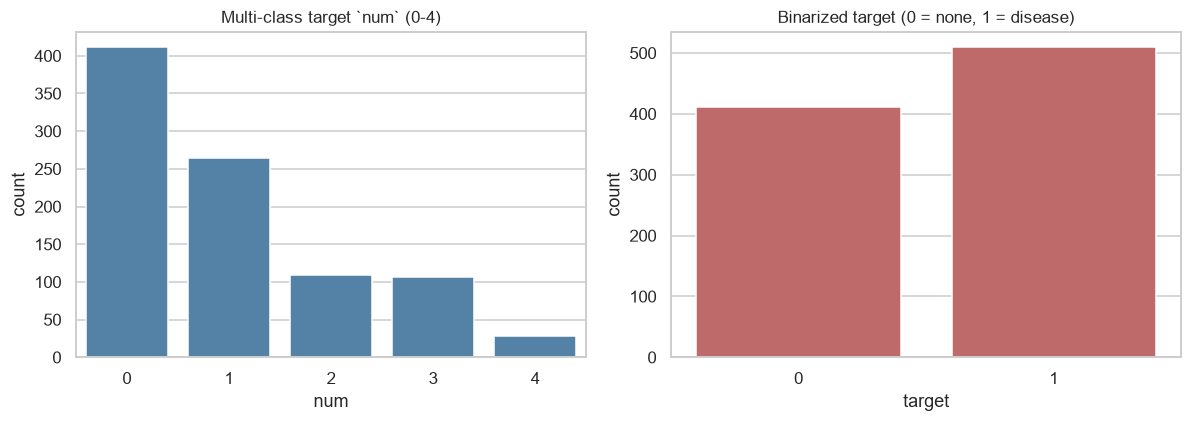

multi-class:
 num
0    411
1    265
2    109
3    107
4     28

binary      
 num
0    411
1    509


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = sorted(raw["num"].unique())
sns.countplot(x="num", data=raw, order=order, ax=axes[0], color="steelblue")
axes[0].set_title("Multi-class target `num` (0-4)")
sns.countplot(x=(raw["num"] > 0).astype(int), ax=axes[1], color="indianred")
axes[1].set_title("Binarized target (0 = none, 1 = disease)")
axes[1].set_xlabel("target")
save_fig("target_distribution")

print("multi-class:\n", raw["num"].value_counts().sort_index().to_string())
print("\nbinary      \n", (raw["num"] > 0).astype(int).value_counts().sort_index().to_string())

### Class balance note
Binarizing `num` yields **410 no-disease / 508 disease (~55% positive)** after
cleaning — close enough to balanced that accuracy is not misleading, but the
clinical framing still prioritizes **recall** (a missed sick patient is the
costly error).

## 2 · Cleaning (rules from `src/data_loader.py`)

In [9]:
df = clean_heart_data(raw)
print("raw:", raw.shape, "-> clean:", df.shape)
df.head()

raw: (920, 16) -> clean: (918, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,target
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [10]:
compare = pd.DataFrame({
    "raw_missing": raw.isna().sum(),
    "clean_missing": df.isna().sum(),
})
compare["raw_missing"] = compare["raw_missing"].fillna(0).astype(int)
compare

,raw_missing,clean_missing
age,0,0.0
ca,611,609.0
chol,30,201.0
cp,0,0.0
dataset,0,NaN
exang,55,55.0
fbs,90,90.0
id,0,NaN
num,0,NaN
oldpeak,62,62.0


In [11]:
# Confirming the zero -> NaN replacement and the dropped duplicates.
print("chol == 0 in clean    :", int((df["chol"] == 0).sum()))
print("trestbps == 0 in clean:", int((df["trestbps"] == 0).sum()))
print("duplicate rows in clean:", df.duplicated().sum())
print("dropped rows           :", raw.shape[0] - df.shape[0])

chol == 0 in clean    : 0
trestbps == 0 in clean: 0
duplicate rows in clean: 0
dropped rows           : 2


### Cleaning decisions
| Column | Action | Why |
|--------|--------|-----|
| `id` | drop | row index, no signal |
| `dataset` | drop | hospital source confounds target (36%–94% disease rate by site) |
| `num` | binarize → `target = num > 0` | clinical yes/no risk framing |
| `chol == 0`, `trestbps == 0` | → `NaN` | physiologically impossible; impute later |
| exact duplicates | drop | 2 rows duplicated once `id` is removed |
| `ca`, `thal` | keep as `NaN` | ~2/3 and ~1/2 missing; impute downstream, never drop silently |

## 3 · Univariate Analysis

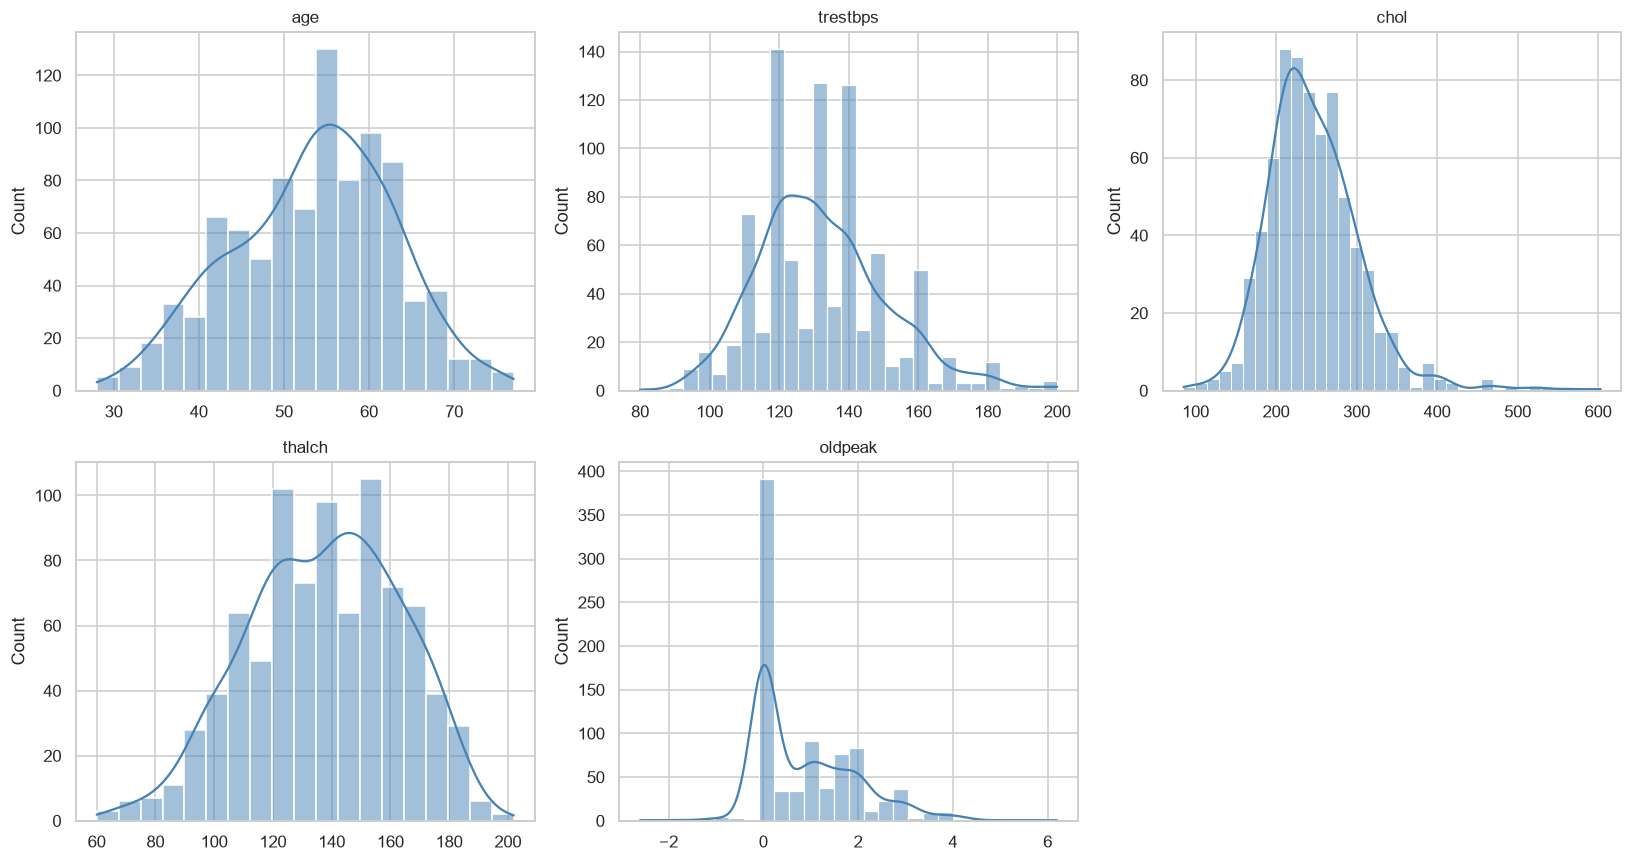

In [12]:
num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
save_fig("univariate_numeric")

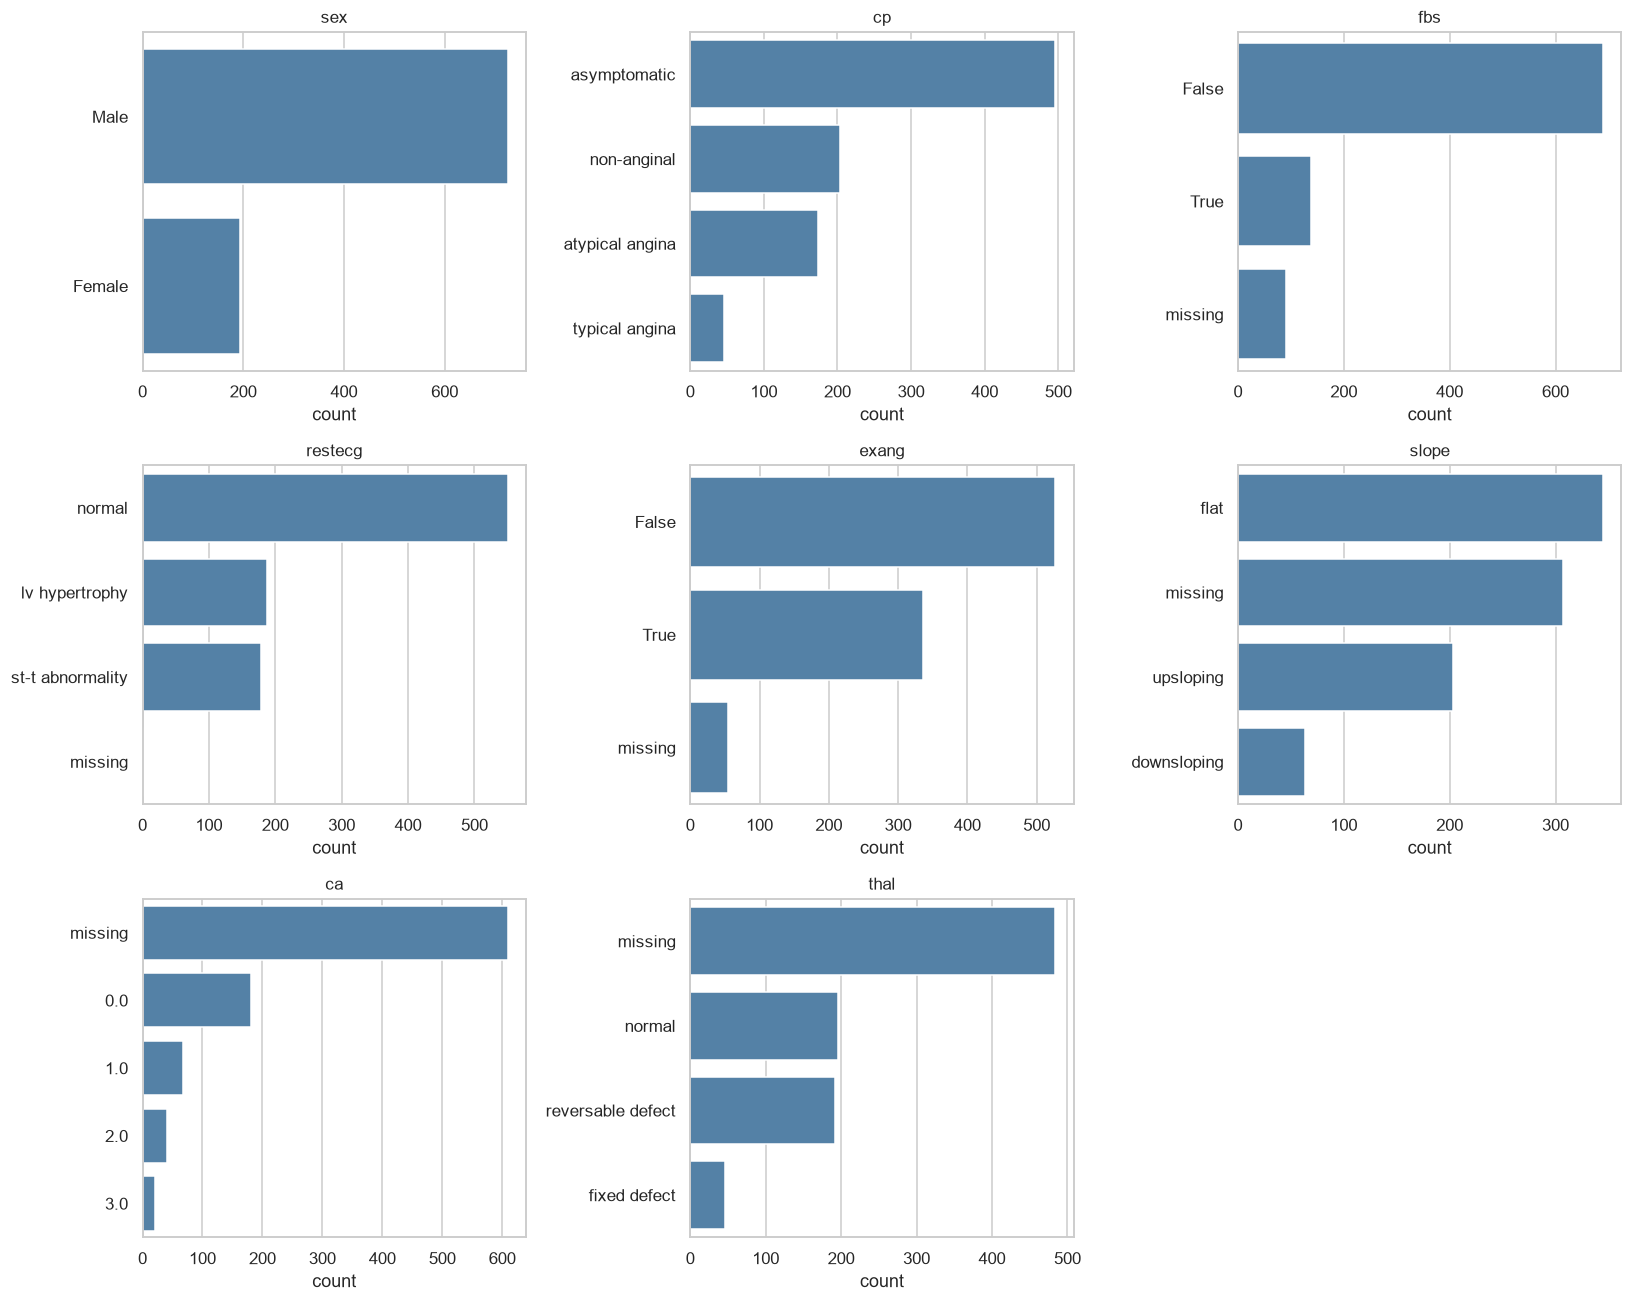

In [13]:
# Levels are cast to string so missing/bool values render cleanly on the axis.
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    series = df[col].astype("object").where(df[col].notna(), "missing").astype(str)
    order = series.value_counts().index
    sns.countplot(y=series, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
save_fig("univariate_categorical")

In [14]:
summary = pd.DataFrame({
    "n_levels": [df[c].nunique(dropna=True) for c in cat_cols],
    "missing_pct": [(df[c].isna().mean() * 100).round(1) for c in cat_cols],
}, index=cat_cols)
summary

,n_levels,missing_pct
sex,2,0.0
cp,4,0.0
fbs,2,9.8
restecg,3,0.2
exang,2,6.0
slope,3,33.4
ca,4,66.3
thal,3,52.7


### Reading the distributions
- `age` is roughly symmetric around ~54; `trestbps` and `chol` are right-skewed
  with a tail of high values (`chol` also carries the 201 imputed-later NaNs).
- `thalch` (max heart rate) is mildly left-skewed; `oldpeak` is heavily
  right-skewed with a large spike at 0.
- `ca` and `thal` are the sparsest features (66% / 53% missing) — visible as the
  large `missing` bar; both are kept and imputed downstream.

## 4 · Bivariate Analysis

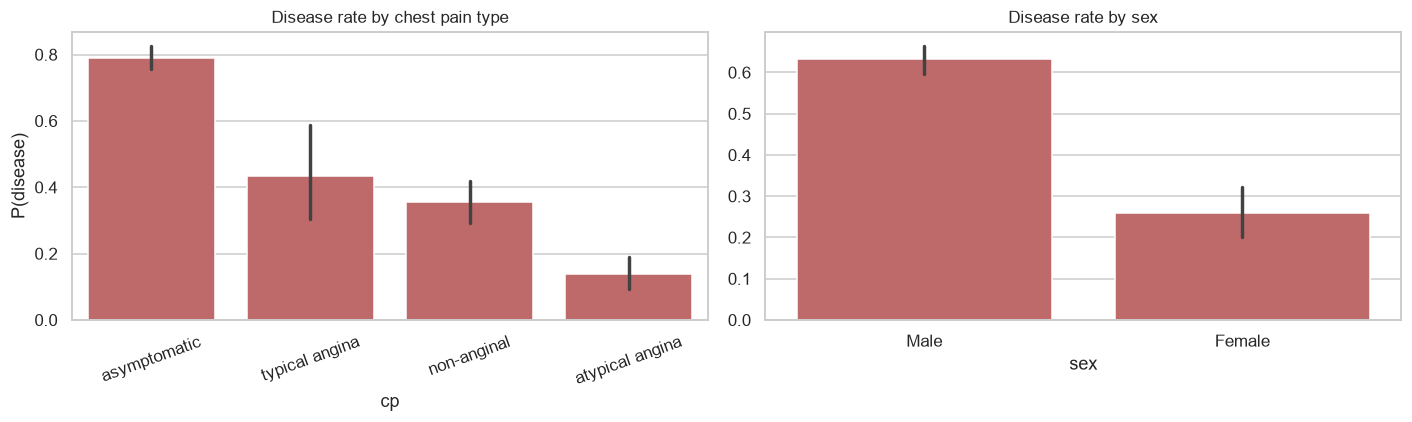

                  mean  size
cp                          
asymptomatic     0.790   496
atypical angina  0.139   173
non-anginal      0.355   203
typical angina   0.435    46

         mean  size
sex                
Female  0.259   193
Male    0.632   725


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="cp", y="target", ax=axes[0], color="indianred",
            order=df.groupby("cp")["target"].mean().sort_values(ascending=False).index)
axes[0].set_title("Disease rate by chest pain type")
axes[0].set_ylabel("P(disease)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="sex", y="target", ax=axes[1], color="indianred")
axes[1].set_title("Disease rate by sex")
axes[1].set_ylabel("")
save_fig("bivariate_rate_cp_sex")

print(df.groupby("cp")["target"].agg(["mean", "size"]).round(3).to_string())
print()
print(df.groupby("sex")["target"].agg(["mean", "size"]).round(3).to_string())

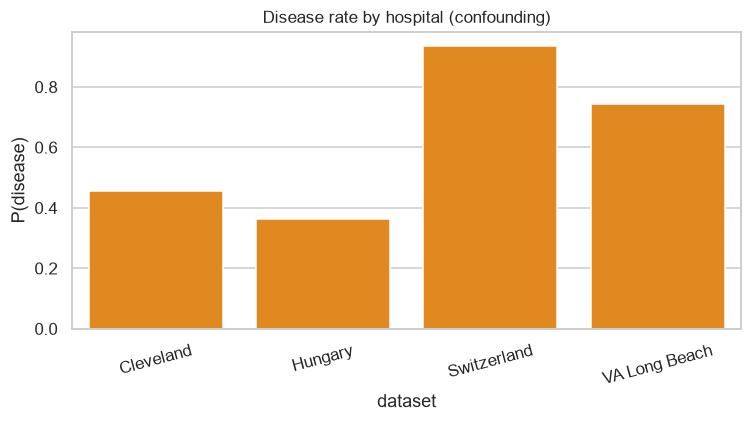

,mean,size
dataset,,
Cleveland,0.457,304
Hungary,0.362,293
Switzerland,0.935,123
VA Long Beach,0.745,200


In [16]:
# `dataset` confounds the target -> justification for dropping it.
raw_rate = (raw.assign(target=(raw["num"] > 0).astype(int))
              .groupby("dataset")["target"].agg(["mean", "size"]))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=raw_rate.index, y=raw_rate["mean"], ax=ax, color="darkorange")
ax.set_title("Disease rate by hospital (confounding)")
ax.set_ylabel("P(disease)")
ax.tick_params(axis="x", rotation=15)
save_fig("bivariate_rate_dataset")
raw_rate.round(3)

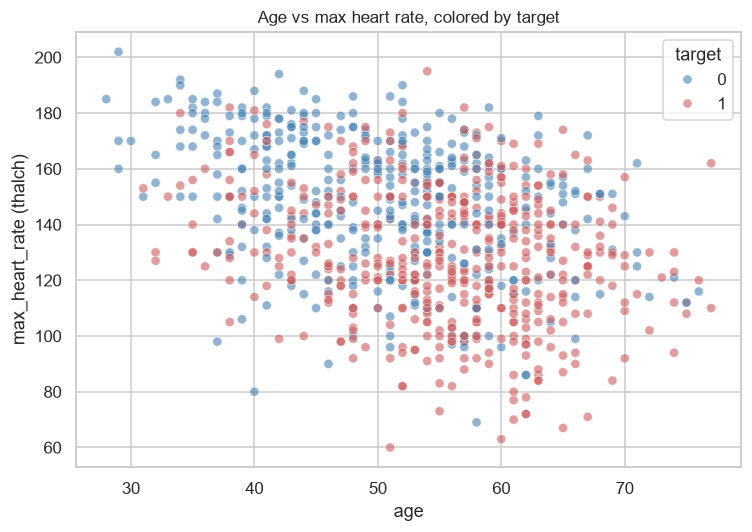

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="thalch", hue="target", alpha=0.6,
                palette={0: "steelblue", 1: "indianred"}, ax=ax)
ax.set_title("Age vs max heart rate, colored by target")
ax.set_ylabel("max_heart_rate (thalch)")
save_fig("bivariate_age_thalch")

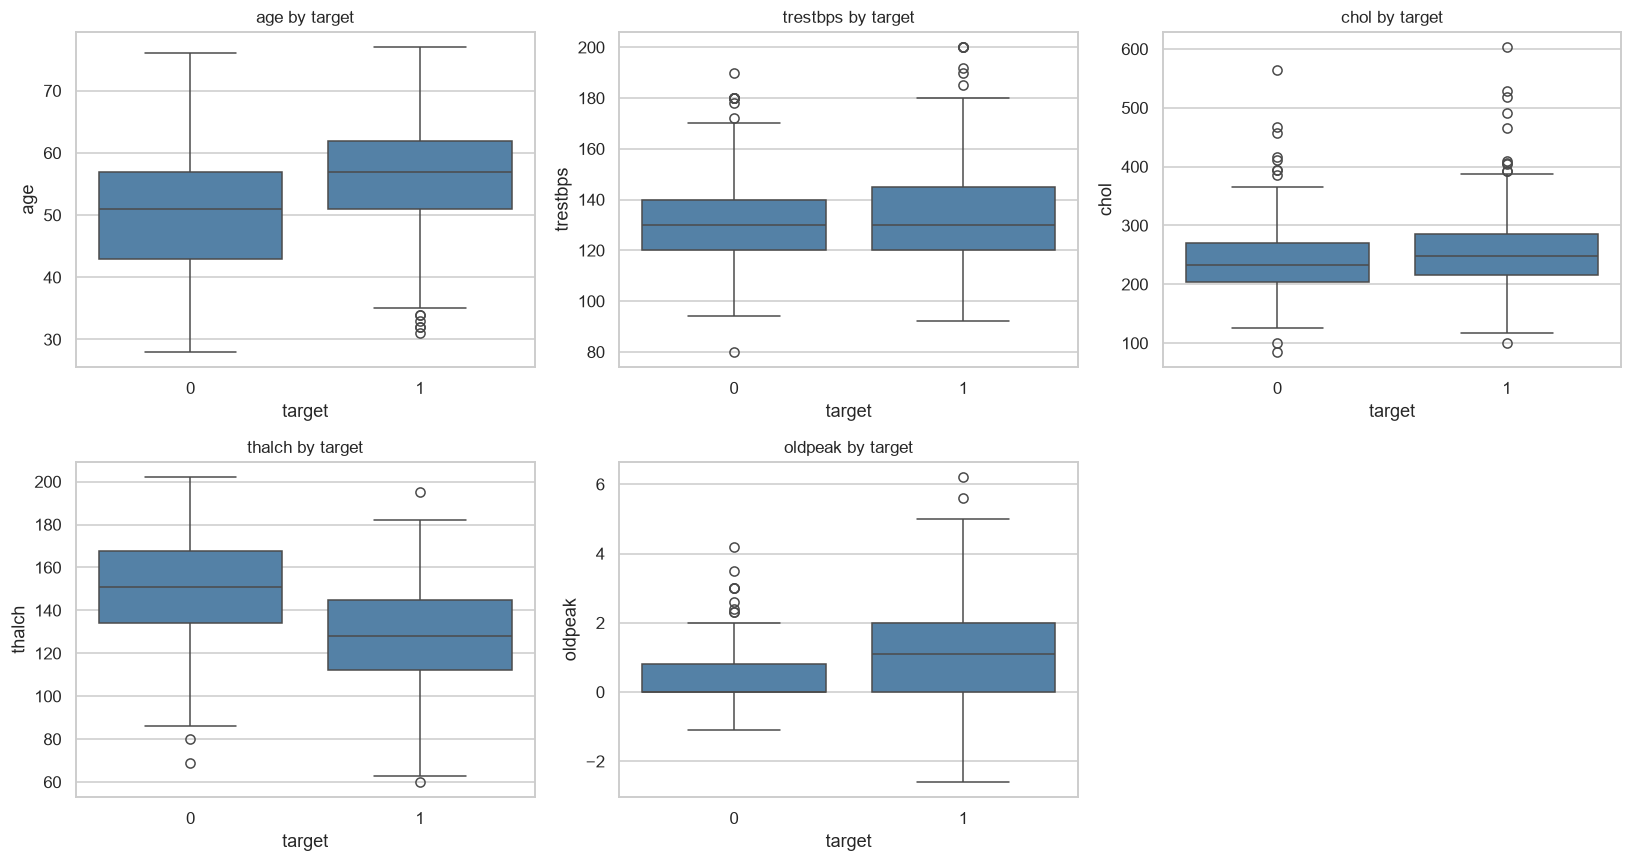

In [18]:
box_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(data=df, x="target", y=col, ax=ax, color="steelblue")
    ax.set_title(f"{col} by target")
for ax in axes.ravel()[len(box_cols):]:
    ax.axis("off")
save_fig("bivariate_boxplots")

### Reading the relationships
- **Chest pain type** is the strongest categorical signal: `asymptomatic`
  patients show the highest disease rate (~79%), while `atypical angina` is ~14%.
- **Sex**: males ~63% vs females ~26% disease rate.
- **Hospital**: disease rate spans 36% (Hungary) to 94% (Switzerland) — a large
  site effect that would leak into the model, confirming `dataset` is dropped.
- **`oldpeak` / `thalch`** separate the classes most cleanly in the boxplots;
  lower max heart rate and higher ST depression track with disease.

## 5 · Correlation Analysis

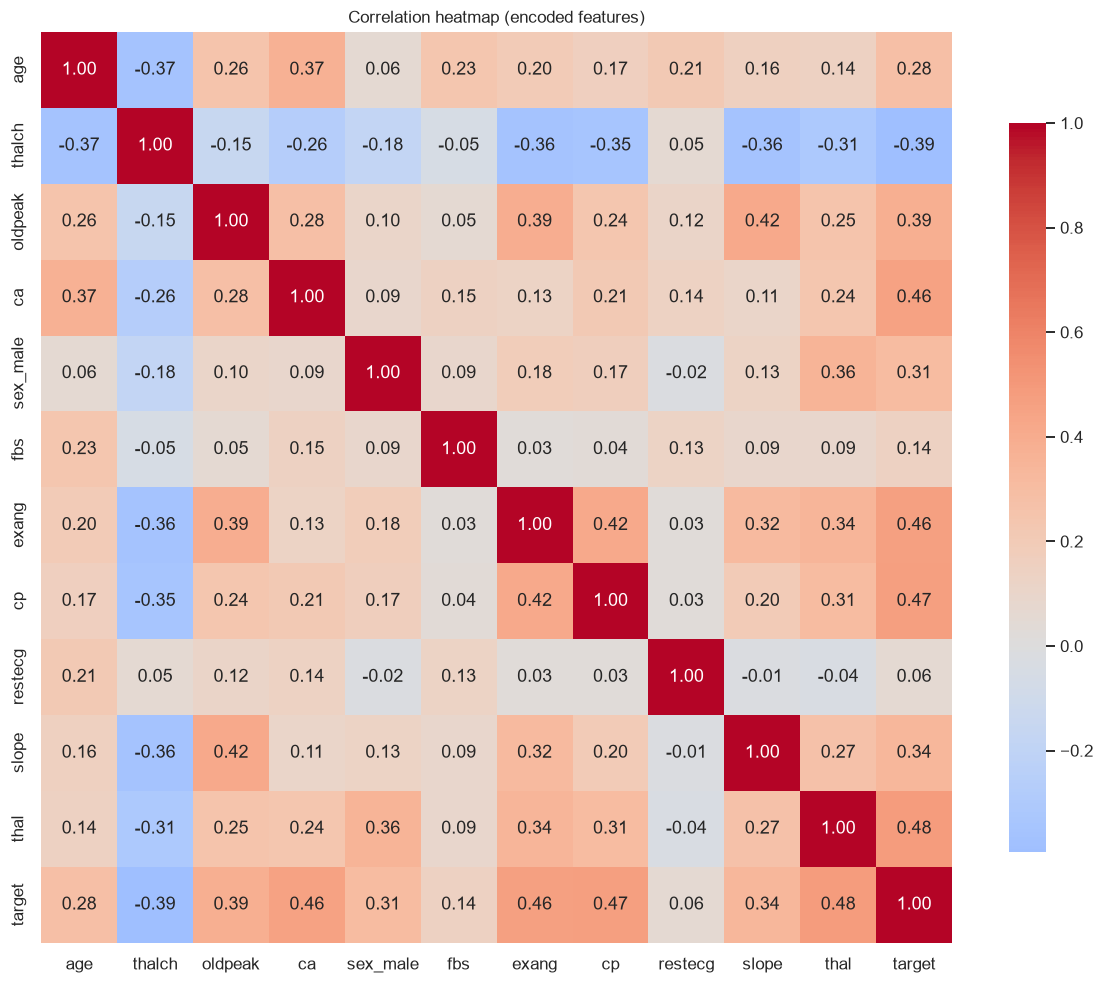

In [19]:
# Numeric-encoded view for correlation. Ordinal mappings are listed explicitly.
enc = pd.DataFrame(index=df.index)
enc["age"] = df["age"]
enc["trestbps"] = df["trestbps"]
enc["chol"] = df["chol"]
enc["thalch"] = df["thalch"]
enc["oldpeak"] = df["oldpeak"]
enc["ca"] = df["ca"]
enc["sex_male"] = (df["sex"] == "Male").astype(int)
enc["fbs"] = df["fbs"].map({True: 1, False: 0})
enc["exang"] = df["exang"].map({True: 1, False: 0})
enc["cp"] = df["cp"].map({"typical angina": 0, "atypical angina": 1,
                          "non-anginal": 2, "asymptomatic": 3})
enc["restecg"] = df["restecg"].map({"normal": 0, "st-t abnormality": 1,
                                    "lv hypertrophy": 2})
enc["slope"] = df["slope"].map({"upsloping": 0, "flat": 1, "downsloping": 2})
enc["thal"] = df["thal"].map({"normal": 0, "fixed defect": 1,
                              "reversable defect": 2})
enc["target"] = df["target"]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(enc.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation heatmap (encoded features)")
save_fig("correlation_heatmap")

In [20]:
# Feature correlation with the target and the slope/oldpeak/exang cluster.
corr_target = enc.corr(numeric_only=True)["target"].drop("target").sort_values()
print("Correlation with target:\n", corr_target.round(3).to_string())

print("\nslope / oldpeak / exang co-movement:")
print(enc[["slope", "oldpeak", "exang"]].corr().round(3).to_string())

Correlation with target:
 thalch     -0.393
restecg     0.063
fbs         0.143
age         0.282
sex_male    0.305
slope       0.337
oldpeak     0.386
ca          0.456
exang       0.462
cp          0.471
thal        0.484

slope / oldpeak / exang co-movement:
         slope  oldpeak  exang
slope    1.000    0.421  0.319
oldpeak  0.421    1.000  0.394
exang    0.319    0.394  1.000


### Reading the correlations
- Strongest positive ties to the target: `exang`, `oldpeak`, `ca`, `cp`, `slope`.
  Strongest negative: `thalch`, `sex_male`.
- `slope`, `oldpeak` and `exang` co-move (exercise-induced angina produces ST
  depression and a pathological slope) — a mild multicollinearity cluster. It does
  not break tree models, but it will matter for linear-model coefficients and SHAP
  attribution (shared credit).